# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** [Input Nama]
- **Email:** [Input Email]
- **ID Dicoding:** [Input Username]

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Kategori produk apa yang menghasilkan total revenue tertinggi dan terendah selama Januari-Agustus 2018, dan kategori mana yang perlu diprioritaskan promosinya?
- **Pertanyaan 2:** Bagaimana tren jumlah order dan total revenue bulanan dari Januari 2017 sampai Agustus 2018, dan bulan mana yang perlu diperkuat kampanyenya?

**Catatan cakupan data:** Revenue dihitung dari `price` pada order berstatus *delivered*. Periode analisis dibatasi Januari 2017 - Agustus 2018 karena data 2016 sangat sedikit dan data September-Oktober 2018 tidak lengkap (dijelaskan pada tahap Assessing Data).

## Import Semua Packages/Library yang Digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mtick

sns.set_theme(style="whitegrid")

## Data Wrangling

### Gathering Data

#### Load seluruh tabel dataset E-Commerce

In [2]:
customers_df = pd.read_csv("data/customers_dataset.csv")
geolocation_df = pd.read_csv("data/geolocation_dataset.csv")
order_items_df = pd.read_csv("data/order_items_dataset.csv")
order_payments_df = pd.read_csv("data/order_payments_dataset.csv")
orders_df = pd.read_csv("data/orders_dataset.csv")
products_df = pd.read_csv("data/products_dataset.csv")
translation_df = pd.read_csv("data/product_category_name_translation.csv")

tables = {
    "customers": customers_df, "geolocation": geolocation_df,
    "order_items": order_items_df, "order_payments": order_payments_df,
    "orders": orders_df, "products": products_df, "translation": translation_df,
}
for name, df in tables.items():
    print(f"{name:15s} baris={df.shape[0]:>8,}  kolom={df.shape[1]}")

orders_df.head()

customers       baris=  99,441  kolom=5
geolocation     baris=1,000,163  kolom=5
order_items     baris= 112,650  kolom=7
order_payments  baris= 103,886  kolom=5
orders          baris=  99,441  kolom=8
products        baris=  32,951  kolom=9
translation     baris=      71  kolom=2


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


**Insight:**
- Tujuh tabel berhasil dimuat. Tabel `orders` (99.441 baris) menjadi poros yang terhubung ke `customers` lewat `customer_id`, ke `order_items` dan `order_payments` lewat `order_id`, lalu ke `products` lewat `product_id`.
- `product_category_name_translation` dipakai untuk menerjemahkan nama kategori dari bahasa Portugis ke Inggris agar mudah dibaca pada visualisasi.

### Assessing Data

#### Identifying missing value problem

In [3]:
print("Missing value tabel orders:")
print(orders_df.isna().sum()[lambda s: s > 0])

print("\nStatus order pada baris yang order_delivered_customer_date-nya kosong:")
print(orders_df[orders_df["order_delivered_customer_date"].isna()]["order_status"].value_counts())

print("\nMissing value tabel products:")
print(products_df.isna().sum()[lambda s: s > 0])

Missing value tabel orders:
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

Status order pada baris yang order_delivered_customer_date-nya kosong:
order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64

Missing value tabel products:
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64


**Steps to Take:**
- Missing value tanggal pada `orders` sebagian besar berasal dari order yang belum terkirim/dibatalkan, jadi bukan kesalahan input. Analisis revenue hanya memakai order berstatus `delivered`.
- Produk tanpa kategori diisi dengan label `unknown` agar tidak hilang dari perhitungan revenue.

#### Identifying data type problem

In [4]:
orders_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


**Steps to Take:**
- Kolom tanggal pada `orders` masih bertipe `object` (string). Ubah ke `datetime` dengan `pd.to_datetime` agar bisa diagregasi per bulan.

#### Identifying inconsistent category name problem

In [5]:
categories_in_products = set(products_df["product_category_name"].dropna().unique())
categories_in_translation = set(translation_df["product_category_name"].unique())
missing_translation = sorted(categories_in_products - categories_in_translation)
print("Kategori yang tidak ada di tabel terjemahan:", missing_translation)

Kategori yang tidak ada di tabel terjemahan: ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']


**Steps to Take:**
- Dua kategori tidak punya terjemahan sehingga akan menjadi NaN setelah merge. Pakai nama aslinya sebagai pengganti.

#### Identifying duplicate data problem

In [6]:
print("Duplikat geolocation:", geolocation_df.duplicated().sum())
print("Duplikat orders      :", orders_df.duplicated().sum())
print("Duplikat order_items :", order_items_df.duplicated().sum())

Duplikat geolocation: 261831
Duplikat orders      : 0
Duplikat order_items : 0


**Steps to Take:**
- Tabel `geolocation` punya ratusan ribu baris duplikat. Hapus dengan `drop_duplicates()`.

#### Identifying incomplete period problem

In [7]:
orders_df["order_purchase_timestamp"] = pd.to_datetime(orders_df["order_purchase_timestamp"])
orders_per_month = orders_df.groupby(orders_df["order_purchase_timestamp"].dt.to_period("M")).size()
print(orders_per_month.to_string())

order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M


**Steps to Take:**
- Data 2016 sangat sedikit dan data September-Oktober 2018 hanya berisi belasan order, sehingga tidak mewakili kondisi sebenarnya. Batasi analisis pada **Januari 2017 - Agustus 2018** agar tren bulanan tidak menyesatkan.

**Insight:**
- Ditemukan lima masalah data: missing value, tipe data tanggal, nama kategori tanpa terjemahan, duplikat pada geolocation (261.831 baris), dan periode data yang tidak lengkap.
- Masalah periode tidak lengkap paling berbahaya karena bisa membuat grafik tren terlihat seolah-olah penjualan anjlok di akhir 2018.

### Cleaning Data

#### Fixing data type problem

In [8]:
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
for col in date_cols:
    orders_df[col] = pd.to_datetime(orders_df[col])

orders_df[date_cols].dtypes

order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

#### Fixing missing value and inconsistent category name problem

In [9]:
products_df["product_category_name"] = products_df["product_category_name"].fillna("unknown")

products_df = products_df.merge(translation_df, on="product_category_name", how="left")
products_df["product_category"] = (products_df["product_category_name_english"]
                                   .fillna(products_df["product_category_name"]))

print("Kategori kosong setelah cleaning:", products_df["product_category"].isna().sum())
products_df[["product_category_name", "product_category"]].drop_duplicates().head()

Kategori kosong setelah cleaning: 0


,product_category_name,product_category
0,perfumaria,perfumery
1,artes,art
2,esporte_lazer,sports_leisure
3,bebes,baby
4,utilidades_domesticas,housewares


#### Fixing duplicate data problem

In [10]:
geolocation_df = geolocation_df.drop_duplicates()
print("Sisa duplikat geolocation:", geolocation_df.duplicated().sum())
print("Jumlah baris geolocation sekarang:", len(geolocation_df))

Sisa duplikat geolocation: 0
Jumlah baris geolocation sekarang: 738332


#### Fixing missing value and incomplete period problem

In [11]:
orders_clean_df = orders_df[
    (orders_df["order_status"] == "delivered")
    & (orders_df["order_purchase_timestamp"] >= "2017-01-01")
    & (orders_df["order_purchase_timestamp"] < "2018-09-01")
].copy()

print("Jumlah order sebelum filter:", len(orders_df))
print("Jumlah order setelah filter:", len(orders_clean_df))
print("Rentang tanggal:", orders_clean_df["order_purchase_timestamp"].min(),
      "s.d.", orders_clean_df["order_purchase_timestamp"].max())

Jumlah order sebelum filter: 99441
Jumlah order setelah filter: 96211
Rentang tanggal: 2017-01-05 11:56:06 s.d. 2018-08-29 15:00:37


**Insight:**
- Setelah cleaning, tersisa 96.211 order *delivered* pada Januari 2017 - Agustus 2018 dari total 99.441 order, sehingga revenue hanya mencerminkan transaksi yang benar-benar selesai.
- Tidak ada lagi kategori kosong, tipe data tanggal sudah benar, dan duplikat geolocation sudah dihapus.

## Exploratory Data Analysis (EDA)

### Explore gabungan data order, produk, dan pelanggan

In [12]:
all_df = (
    order_items_df
    .merge(orders_clean_df[["order_id", "customer_id", "order_purchase_timestamp"]], on="order_id", how="inner")
    .merge(products_df[["product_id", "product_category"]], on="product_id", how="left")
    .merge(customers_df[["customer_id", "customer_unique_id", "customer_state"]], on="customer_id", how="left")
)
all_df["product_category"] = all_df["product_category"].fillna("unknown")
all_df["order_month"] = all_df["order_purchase_timestamp"].dt.to_period("M").astype(str)
all_df["order_year"] = all_df["order_purchase_timestamp"].dt.year

print("Bentuk data gabungan:", all_df.shape)
all_df[["price", "freight_value"]].describe()

Bentuk data gabungan: (109880, 14)


,price,freight_value
count,109880.000000,109880.000000
mean,119.958383,19.949881
std,182.346158,15.703594
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.900000,16.260000
75%,134.170000,21.150000
max,6735.000000,409.680000


### Explore revenue per kategori produk (Januari-Agustus 2018)

In [13]:
df_2018 = all_df[all_df["order_year"] == 2018]

category_revenue = (df_2018.groupby("product_category")
                    .agg(revenue=("price", "sum"), items_sold=("order_id", "count"))
                    .sort_values("revenue", ascending=False))

print("Total revenue Jan-Agu 2018: R$ {:,.0f}".format(category_revenue["revenue"].sum()))
print("Jumlah kategori terjual     :", len(category_revenue))
print("\n5 kategori revenue tertinggi:")
print(category_revenue.head(5).round(0))
print("\n5 kategori revenue terendah:")
print(category_revenue.tail(5).round(0))

top5_share = category_revenue["revenue"].head(5).sum() / category_revenue["revenue"].sum()
print("\nKontribusi 5 kategori teratas: {:.1%}".format(top5_share))

Total revenue Jan-Agu 2018: R$ 7,218,125
Jumlah kategori terjual     : 73

5 kategori revenue tertinggi:
                        revenue  items_sold
product_category                           
health_beauty          755724.0        5841
watches_gifts          687855.0        3628
bed_bath_table         532359.0        5810
sports_leisure         517166.0        4436
computers_accessories  496269.0        4622

5 kategori revenue terendah:
                           revenue  items_sold
product_category                              
fashio_female_clothing       617.0          16
fashion_sport                370.0           5
fashion_childrens_clothes    170.0           3
home_comfort_2               151.0          10
cds_dvds_musicals             65.0           1

Kontribusi 5 kategori teratas: 41.4%


### Explore tren order dan revenue bulanan

In [14]:
monthly_df = (all_df.groupby("order_month")
              .agg(order_count=("order_id", "nunique"), revenue=("price", "sum"))
              .reset_index())
monthly_df["revenue_mom_pct"] = monthly_df["revenue"].pct_change() * 100
print(monthly_df.round(1).to_string(index=False))

rev_jan_aug_2017 = all_df[(all_df["order_year"] == 2017) & (all_df["order_purchase_timestamp"].dt.month <= 8)]["price"].sum()
rev_jan_aug_2018 = all_df[all_df["order_year"] == 2018]["price"].sum()
print("\nRevenue Jan-Agu 2017: R$ {:,.0f}".format(rev_jan_aug_2017))
print("Revenue Jan-Agu 2018: R$ {:,.0f}".format(rev_jan_aug_2018))
print("Pertumbuhan YoY      : {:.1%}".format(rev_jan_aug_2018 / rev_jan_aug_2017 - 1))

order_month  order_count  revenue  revenue_mom_pct
    2017-01          750 111798.4              NaN
    2017-02         1653 234223.4            109.5
    2017-03         2546 359198.8             53.4
    2017-04         2303 340669.7             -5.2
    2017-05         3546 489338.2             43.6
    2017-06         3135 421923.4            -13.8
    2017-07         3872 481604.5             14.1
    2017-08         4193 554699.7             15.2
    2017-09         4150 607399.7              9.5
    2017-10         4478 648247.6              6.7
    2017-11         7289 987765.4             52.4
    2017-12         5513 726033.2            -26.5
    2018-01         7069 924645.0             27.4
    2018-02         6555 826437.1            -10.6
    2018-03         7003 953356.2             15.4
    2018-04         6798 973534.1              2.1
    2018-05         6749 977544.7              0.4
    2018-06         6099 856077.9            -12.4
    2018-07         6159 867953

**Insight:**
- Total revenue Januari-Agustus 2018 adalah R$ 7,22 juta dari 73 kategori. Lima kategori teratas (`health_beauty`, `watches_gifts`, `bed_bath_table`, `sports_leisure`, `computers_accessories`) menyumbang 41,4% dari total revenue.
- Revenue Januari-Agustus 2018 tumbuh 141,1% dibanding periode yang sama tahun 2017 (R$ 2,99 juta menjadi R$ 7,22 juta). Namun sejak Maret 2018 jumlah order cenderung turun dari 7.003 menjadi 6.351 pada Agustus 2018.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Kategori produk dengan revenue tertinggi dan terendah (Jan-Agu 2018)

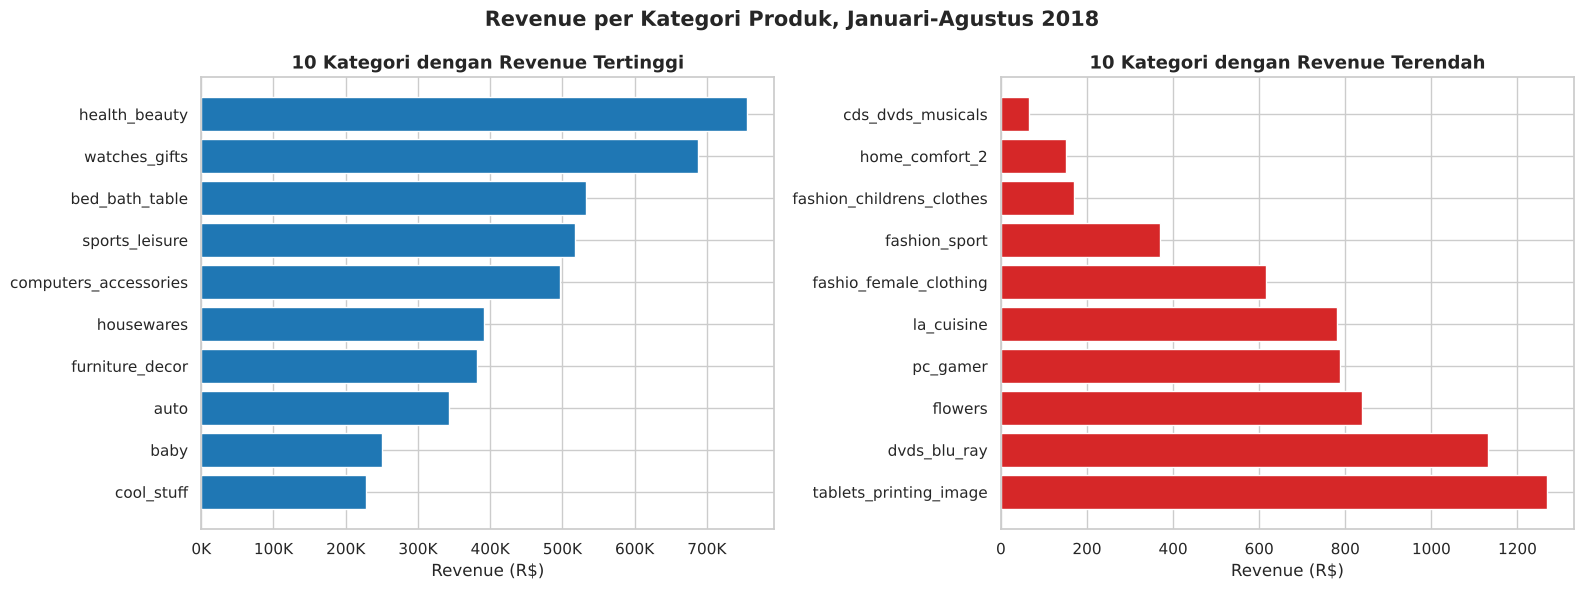

In [15]:
top10 = category_revenue["revenue"].head(10).sort_values()
bottom10 = category_revenue["revenue"].tail(10).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].barh(top10.index, top10.values, color="#1f77b4")
axes[0].set_title("10 Kategori dengan Revenue Tertinggi", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Revenue (R$)")
axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1000:,.0f}K"))

axes[1].barh(bottom10.index, bottom10.values, color="#d62728")
axes[1].set_title("10 Kategori dengan Revenue Terendah", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Revenue (R$)")

for ax in axes:
    ax.set_ylabel("")
    ax.set_xlim(left=0)   # bar chart selalu mulai dari nol agar tidak menyesatkan

fig.suptitle("Revenue per Kategori Produk, Januari-Agustus 2018", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

**Insight:** `health_beauty` memimpin dengan revenue sekitar R$ 756 ribu, disusul `watches_gifts` (R$ 688 ribu) dan `bed_bath_table` (R$ 532 ribu). Menariknya `watches_gifts` terjual hanya 3.628 item tetapi revenue-nya kedua, karena harga rata-rata per item tinggi (sekitar R$ 190 dibanding sekitar R$ 92 pada `bed_bath_table`). Di sisi terendah, `cds_dvds_musicals` hanya menghasilkan R$ 65 dari 1 item, dan `fashion_childrens_clothes` R$ 170 dari 3 item. Kategori terbawah ini praktis tidak berkontribusi terhadap bisnis. Catatan: penulisan `fashio_female_clothing` memang salah ketik dari dataset aslinya.

### Pertanyaan 2: Tren order dan revenue bulanan (Jan 2017 - Agu 2018)

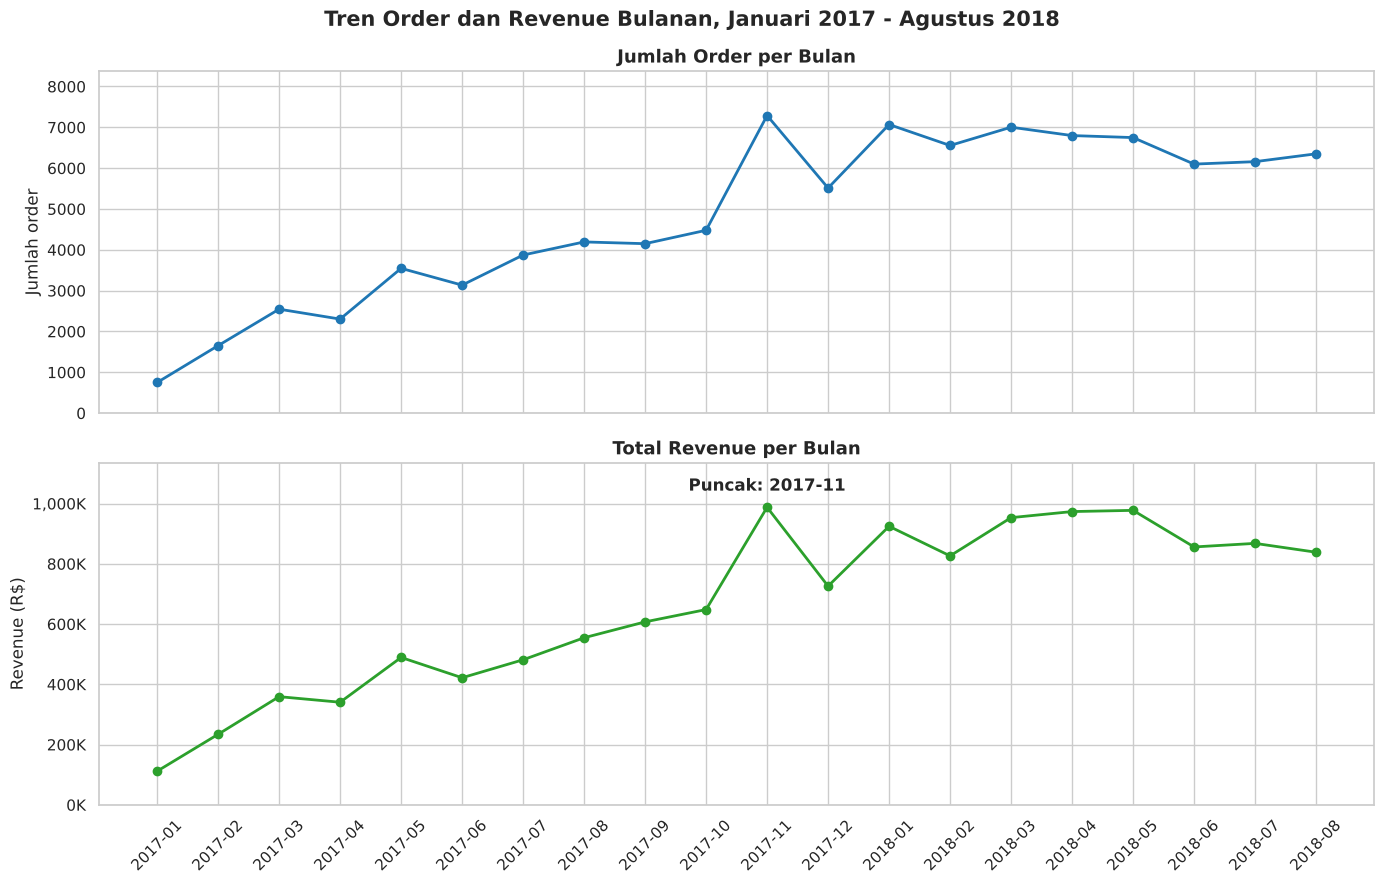

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
x = monthly_df["order_month"]

axes[0].plot(x, monthly_df["order_count"], marker="o", color="#1f77b4", linewidth=2)
axes[0].set_title("Jumlah Order per Bulan", fontsize=13, fontweight="bold")
axes[0].set_ylabel("Jumlah order")

axes[1].plot(x, monthly_df["revenue"], marker="o", color="#2ca02c", linewidth=2)
axes[1].set_title("Total Revenue per Bulan", fontsize=13, fontweight="bold")
axes[1].set_ylabel("Revenue (R$)")
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1000:,.0f}K"))

peak = monthly_df.loc[monthly_df["revenue"].idxmax()]
axes[1].annotate(f"Puncak: {peak['order_month']}", xy=(peak["order_month"], peak["revenue"]),
                 xytext=(0, 12), textcoords="offset points", ha="center", fontweight="bold")

axes[0].set_ylim(0, monthly_df["order_count"].max() * 1.15)  # sumbu y mulai dari nol
axes[1].set_ylim(0, monthly_df["revenue"].max() * 1.15)
plt.xticks(rotation=45)
fig.suptitle("Tren Order dan Revenue Bulanan, Januari 2017 - Agustus 2018", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

**Insight:** Jumlah order dan revenue naik tajam sepanjang 2017 dan mencapai puncak pada November 2017 (7.289 order, R$ 988 ribu, naik 52,4% dari bulan sebelumnya), kemungkinan karena momentum Black Friday. Setelah itu Desember 2017 turun 26,5%. Sepanjang 2018 pertumbuhan mendatar di kisaran R$ 826 ribu - R$ 978 ribu per bulan. Revenue mencapai puncak 2018 pada Mei (R$ 978 ribu), lalu turun 12,4% pada Juni dan bertahan rendah hingga Agustus (R$ 839 ribu).

## Analisis Lanjutan (Opsional)

### RFM Analysis dan Manual Grouping

RFM mengelompokkan pelanggan (`customer_unique_id`) berdasarkan perilaku belanja:
- **Recency:** jumlah hari sejak transaksi terakhir pelanggan.
- **Frequency:** jumlah order pelanggan.
- **Monetary:** total nilai pembayaran pelanggan.

Karena mayoritas pelanggan hanya membeli satu kali, nilai *frequency* nyaris seragam sehingga tidak cocok dibagi dengan kuartil. Karena itu dipakai **binning kuartil** untuk Recency dan Monetary, dan **manual grouping** (aturan bisnis) untuk Frequency (sekali beli vs repeat).

In [17]:
snapshot_date = all_df["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

order_pay_df = order_payments_df.groupby("order_id", as_index=False)["payment_value"].sum()
rfm_base = (orders_clean_df[["order_id", "customer_id", "order_purchase_timestamp"]]
            .merge(customers_df[["customer_id", "customer_unique_id"]], on="customer_id")
            .merge(order_pay_df, on="order_id"))

rfm_df = (rfm_base.groupby("customer_unique_id")
          .agg(last_purchase=("order_purchase_timestamp", "max"),
               frequency=("order_id", "nunique"),
               monetary=("payment_value", "sum"))
          .reset_index())
rfm_df["recency"] = (snapshot_date - rfm_df["last_purchase"]).dt.days

# Binning kuartil: skor 4 = terbaik
rfm_df["r_score"] = pd.qcut(rfm_df["recency"], 4, labels=[4, 3, 2, 1]).astype(int)
rfm_df["m_score"] = pd.qcut(rfm_df["monetary"], 4, labels=[1, 2, 3, 4]).astype(int)

# Manual grouping berdasarkan aturan bisnis
conditions = [
    (rfm_df["frequency"] >= 2) & (rfm_df["r_score"] >= 3),
    (rfm_df["frequency"] >= 2),
    (rfm_df["r_score"] >= 3) & (rfm_df["m_score"] >= 3),
    (rfm_df["r_score"] >= 3),
    (rfm_df["m_score"] >= 3),
]
labels = ["Repeat Aktif", "Repeat Tidak Aktif", "Baru Bernilai Tinggi", "Baru Bernilai Rendah", "Berisiko Hilang (Nilai Tinggi)"]
rfm_df["segment"] = np.select(conditions, labels, default="Tidak Aktif")

print("Total pelanggan unik:", len(rfm_df))
print("Pelanggan repeat (>=2 order): {:.1%}".format((rfm_df["frequency"] >= 2).mean()))
print()
segment_summary = (rfm_df.groupby("segment")
                   .agg(customers=("customer_unique_id", "count"),
                        avg_recency_days=("recency", "mean"),
                        avg_frequency=("frequency", "mean"),
                        avg_monetary=("monetary", "mean"))
                   .sort_values("customers", ascending=False))
segment_summary["share_pct"] = segment_summary["customers"] / segment_summary["customers"].sum() * 100
segment_summary.round(1)

Total pelanggan unik: 93104
Pelanggan repeat (>=2 order): 3.0%



,customers,avg_recency_days,avg_frequency,avg_monetary,share_pct
segment,,,,,
Tidak Aktif,23627,362.5,1.0,63.8,25.4
Baru Bernilai Rendah,22600,111.5,1.0,63.0,24.3
Baru Bernilai Tinggi,22430,111.4,1.0,261.2,24.1
Berisiko Hilang (Nilai Tinggi),21658,362.1,1.0,264.3,23.3
Repeat Aktif,1534,112.2,2.1,315.1,1.6
Repeat Tidak Aktif,1255,350.9,2.1,300.8,1.3


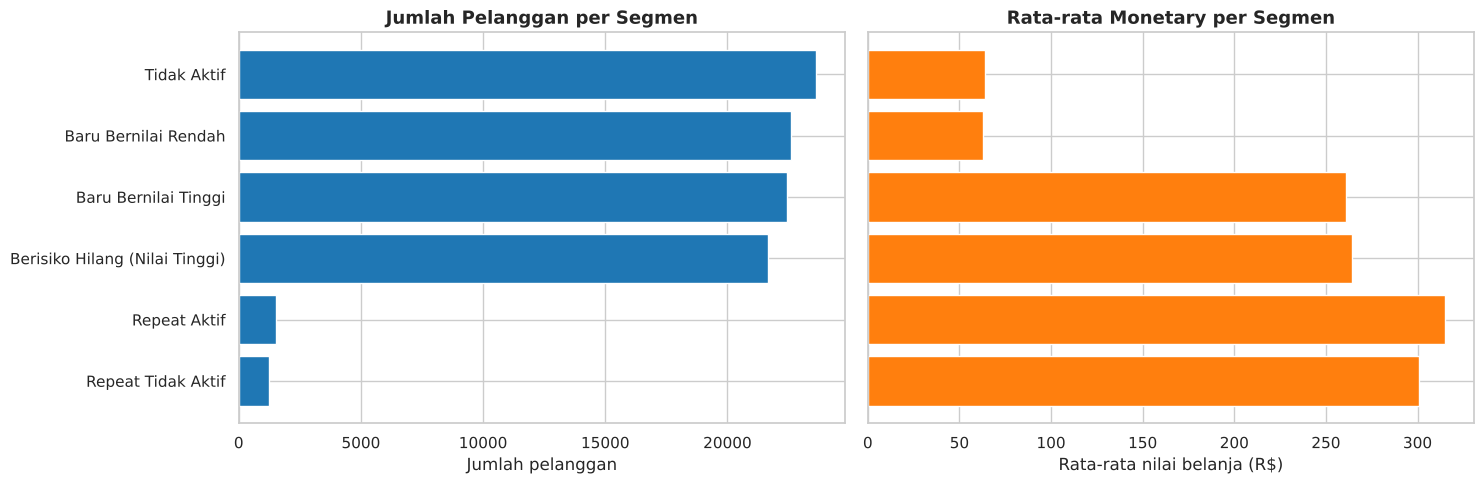

In [18]:
order_seg = segment_summary.sort_values("customers")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].barh(order_seg.index, order_seg["customers"], color="#1f77b4")
axes[0].set_title("Jumlah Pelanggan per Segmen", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Jumlah pelanggan")

axes[1].barh(order_seg.index, order_seg["avg_monetary"], color="#ff7f0e")
axes[1].set_title("Rata-rata Monetary per Segmen", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Rata-rata nilai belanja (R$)")
axes[1].set_yticklabels([])

for ax in axes:
    ax.set_xlim(left=0)
plt.tight_layout()
plt.show()

**Insight:**
- Dari 93.104 pelanggan unik, hanya 3,0% yang pernah membeli lebih dari satu kali. Sebagian besar pelanggan (sekitar 97%) adalah pembeli sekali beli, sehingga retensi menjadi kelemahan utama.
- Segmen `Baru Bernilai Tinggi` (22.430 pelanggan, rata-rata belanja R$ 261, terakhir beli sekitar 111 hari lalu) adalah peluang terbesar untuk dijadikan pelanggan repeat. Segmen `Berisiko Hilang (Nilai Tinggi)` (21.658 pelanggan, rata-rata R$ 264, terakhir beli sekitar 362 hari lalu) adalah target win-back. Pelanggan `Repeat Aktif` hanya 1,6% tetapi rata-rata belanjanya tertinggi (R$ 315).

### Export Data untuk Dashboard

In [19]:
import os
os.makedirs("dashboard", exist_ok=True)

main_cols = ["order_id", "order_purchase_timestamp", "order_month", "product_category",
             "price", "freight_value", "customer_unique_id", "customer_state"]
all_df[main_cols].to_csv("dashboard/main_data.csv", index=False)
rfm_df.drop(columns=["last_purchase"]).to_csv("dashboard/rfm_data.csv", index=False)
print("main_data.csv :", len(all_df), "baris")
print("rfm_data.csv  :", len(rfm_df), "baris")

main_data.csv : 109880 baris
rfm_data.csv  : 93104 baris


## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Pada Januari-Agustus 2018, `health_beauty` adalah kategori dengan revenue tertinggi (sekitar R$ 756 ribu), diikuti `watches_gifts` dan `bed_bath_table`. Lima kategori teratas menyumbang 41,4% revenue. Kategori dengan revenue terendah seperti `cds_dvds_musicals`, `fashion_childrens_clothes`, dan `home_comfort_2` hanya menghasilkan kurang dari R$ 200 per kategori.
- **Conclusion pertanyaan 2:** Order dan revenue tumbuh kuat dari Januari 2017 hingga puncaknya pada November 2017, lalu mendatar sepanjang 2018. Penurunan terjadi pada Juni-Agustus 2018: revenue Agustus 2018 (R$ 839 ribu) berada sekitar 14% di bawah puncak Mei 2018 (R$ 978 ribu), dan jumlah order Agustus turun sekitar 10% dari Januari 2018.
- **Conclusion analisis lanjutan (RFM):** Hanya 3,0% pelanggan yang pernah repeat order. Peluang pertumbuhan terbesar ada pada mengubah pelanggan baru bernilai tinggi menjadi pelanggan repeat dan memenangkan kembali pelanggan bernilai tinggi yang sudah lama tidak membeli.

**Rekomendasi Action Item:**
- **Pertahankan dan perkuat kategori unggulan.** Prioritaskan promosi dan stok untuk `health_beauty`, `watches_gifts`, dan `bed_bath_table`. Untuk `watches_gifts`, fokuskan pada produk bernilai tinggi karena kontribusi revenue per item-nya besar.
- **Evaluasi kategori revenue terendah.** Kategori dengan revenue di bawah R$ 1.000 per periode perlu dievaluasi: tingkatkan promosi bila potensinya masih ada, atau kurangi alokasi stok dan iklan bila tidak.
- **Kuatkan kampanye di bulan lemah.** Buat kampanye khusus pada Juni-Agustus (periode penurunan 2018) dan Februari, serta siapkan kampanye musiman November untuk mengulang lonjakan 2017. Kampanye Desember juga perlu agar penurunan setelah puncak November lebih kecil.
- **Bangun program retensi.** Kirim voucher atau email follow-up 30-60 hari setelah pembelian kepada segmen `Baru Bernilai Tinggi`, dan kirim penawaran win-back kepada segmen `Berisiko Hilang (Nilai Tinggi)`. Target awalnya menaikkan proporsi pelanggan repeat dari 3,0%.